# CB 4. Stat 4770/7770. Fall 2026

## Introduction

* In this coding brick you will download and analyze a data set, fitting both statistical regression models and machine learning models.
* The Module 7 and 8 notes contain examples of fitting all these sorts of models, so if you get stuck they will make a good reference point.
* The data set is the credit scoring dataset called PRSM. If you want to learn more about the background business problem and see a list of all the variables, there is a document on Canvas in the homework folder called "PRSM_intro_4770_7707.pdf".
* If you have multiple Axes level plots in a cell, then putting the command plt.show() after each one will make sure that they are all printed.

## Q1. Read in and review the data structure
### 4 pts.

* The data file to download is called "PRSM_data".

a. Download the the data from the Canvas "csv" folder, to your computer and then into a pandas DataFrame. Call the data frame "prsm_data". Use the column called "CaseNumber" as the row index variable.

b. Use the .info() method to summarize and print the data frame structure.

In [1]:
import numpy as np
np.set_printoptions(precision=6)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Remove warnings
import warnings
warnings.filterwarnings('ignore')

# Change and uncomment this filepath to the location where you downloaded the data set.
# os.chdir('C:\\Users\\water\\Penn Dropbox\\Richard Waterman\\Richard\\Teaching\\7770f2026_Q1\\DataSets') 

#1a. (2pts.)

prsm_data = pd.read_csv("PRSM_data.csv", index_col = "CaseNumber")

#1b. (2pts.)

print("1b:\n")
prsm_data.info()


1b:

<class 'pandas.DataFrame'>
Index: 999 entries, 297918523 to 95627938
Data columns (total 40 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   PRSM                                     999 non-null    float64
 1   Amt.Repaid.at.6.Months                   999 non-null    int64  
 2   Nominal.Loan.Amount                      999 non-null    float64
 3   Total.Amt.to.be.Repaid                   999 non-null    float64
 4   Repayment.Percentage                     999 non-null    float64
 5   Commission.Upfront                       999 non-null    float64
 6   Validated.Monthly.Batch                  999 non-null    float64
 7   Historical.Monthly.Credit.Card.Receipts  999 non-null    float64
 8   Months.of.History                        999 non-null    int64  
 9   Loan.Type                                999 non-null    str    
 10  FICO                                     999 non

## Q2. Plot the distribution of PRSM score
### 6 pts.

a. Using the seaborn library, plot the distribution of the PRSM variable, using a histogram and KDE. 

b. Create a box plot of the PRSM variable.

c. From parts a and b, describe any anomalies that you see in the distribution of PRSM, remembering that PRSM is a measure of how much of the loan has been repaid and would expected to be above 0.


2a:



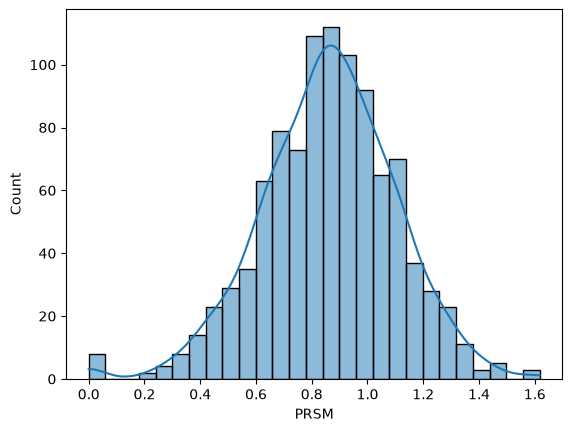


2b:



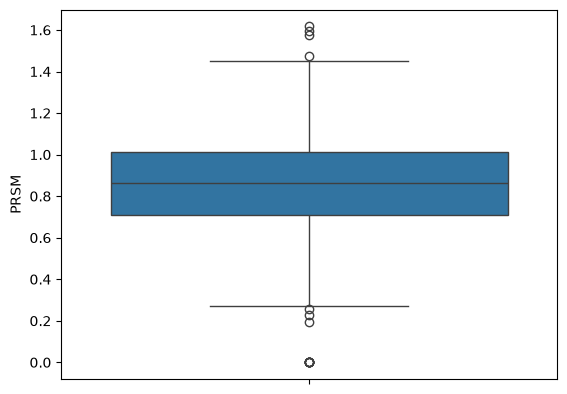


2c: There are a few loans, as seen by the outlier of the box plot, that have a PRSM of 0.0, meaning none of the loan was repaid, which is an abnormality


In [2]:
#2a. (2pts.)

print("2a:\n")
sns.histplot(data = prsm_data, x = "PRSM", kde = True);
plt.show()
 
#2b. (2pts.)
print("\n2b:\n")
sns.boxplot(prsm_data["PRSM"]);
plt.show()

#2c. (2pts.) Your answer here. 

print("\n2c: There are a few loans, as seen by the outlier of the box plot, that have a PRSM of 0.0, meaning none of the loan was repaid, which is an abnormality")


## Q3 Explore the relationship between PRSM score and FICO score
### 5 pts.

a. Using seaborn's regplot, plot a simple regression of PRSM against FICO.

b. Using seaborn's relplot, make a color coded scatterplot of PRSM score and FICO score, colored (hue) by Loan.Type.

c. Finally using 'lmplot' show a regression line for each level of LoanType (still using PRSM against FICO).  
 
d. Comment on which of the three models, one line fits all, parallel lines or interaction seems more suitable to use as a model based on your graphs.  

3a: 



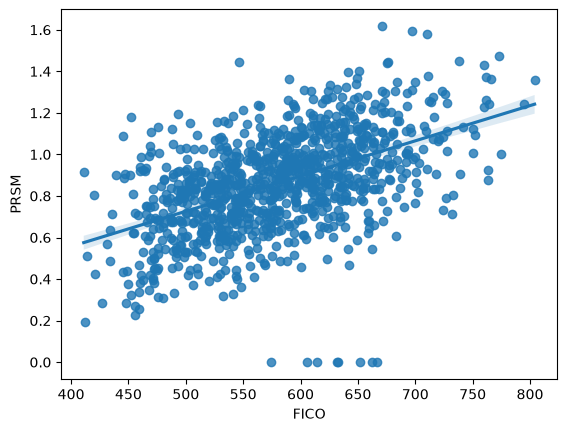


3b: 



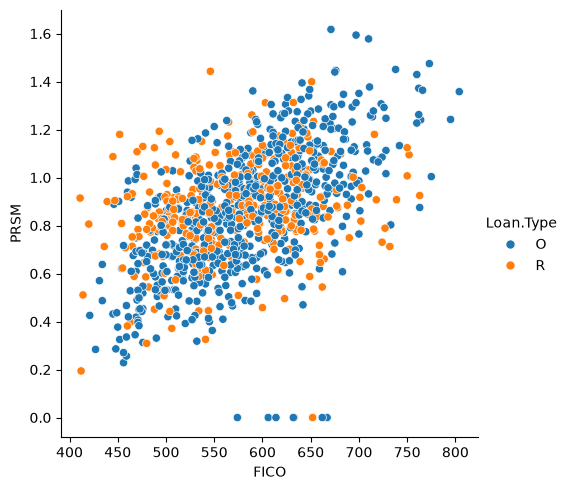


3c:



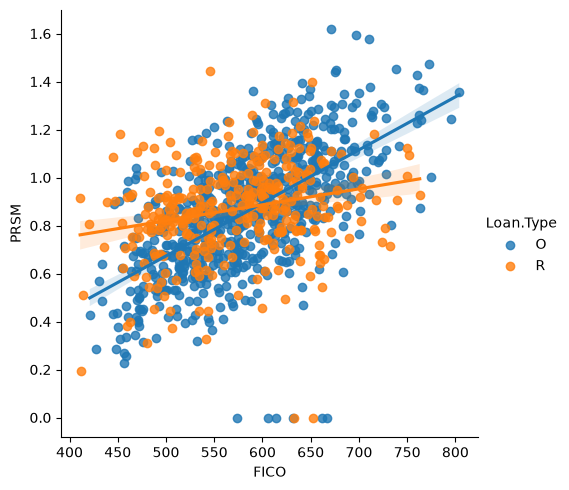


3d: The interaction model is the most suitable since the regression lines for the two Loan.Type categories have quite different slopes and intersect, showing that FICO score on PRSM depends on the loan type, as seen in 3c.


In [3]:
# Q3 code goes here

#3a. (1pt.)

print("3a: \n")
sns.regplot(data = prsm_data, y = "PRSM", x = "FICO");
plt.show()

#3b. (1pt.)

print("\n3b: \n")
sns.relplot(data = prsm_data, y = "PRSM", x = "FICO", hue = "Loan.Type")
plt.show()

#3c. (2pts.)

print("\n3c:\n")
sns.lmplot(data = prsm_data, y = "PRSM", x = "FICO", hue = "Loan.Type")
plt.show()
  
#3d. (1pt.) Your comment here. 
print("\n3d: The interaction model is the most suitable since the regression lines for the two Loan.Type categories have quite different slopes and intersect, showing that FICO score on PRSM depends on the loan type, as seen in 3c.")

## Q4 Fit a simple regression model to the data.
### 8 pts.

a. Using the stats models library, fit a simple regression of PRSM v. FICO and print its summary output.

b. Interpret the R-squared value.

c. For two loans whose FICO score differs by 50, what does the model predict their *difference* in PRSM score will be? Do this calculation using Python and not "by hand". You can extract the  model coefficients from the fitted regression object using the ".params" attribute. 

d. Based on the p-value of the FICO score, does it appear that this variable is an important predictor of PRSM? Explain your reasoning.

e. Create a data frame for prediction (call it Xnew) that has a single column named "FICO" and two values, 650 and 700. Print the data frame.

f. Using the .predict method, predict and print the PRSM score for these two loans.

g. There is an attribute in the regression output called "mse_resid", the mean squared error. If you called your fitted model olsres1, then you get the MSE with the command 'olsres1.mse_resid'. Use Python to calculate the ***ROOT*** MSE.

h. Approximately how wide (the distance from the center to the edge) would a 95% prediction interval be for the predictions you made in part 4f? This is called the "margin of error" for the predictions.



In [4]:
import statsmodels.formula.api as smf
import math

#Q4a. (1pt.)

print("4a:\n")
model = smf.ols(data = prsm_data, formula = "PRSM ~ FICO").fit()
print(model.summary())

#Q4b. (1pt.) Your answer here. 

print("\n4b: The R-squared value says that 25.2% of variance in PRSM is explained by FICO score in this model, which is not a high R-squared")

#Q4c. (1pt.)

print("\n4c: \n")
print(model.params)
print("\nThe model predicts the difference between two loans whose FICO score differ by 50 is 50 * 0.model.params[FICO] = " + str(50 * model.params["FICO"]))

#Q4d. (1pt.) Your answer here. 

print("\n4d: Based on the p value of the model, that being 0.000, it can be stated that the FICO variable is an important predictor of PRSM since the p value <= 0.05")

#Q4e. (1pt.)

print("\n4e: \n")
Xnew = pd.DataFrame({"FICO": [650, 700]})
print(Xnew)

 
#Q4f. (1pt.)

print("\n4f:\n")
print(model.predict(Xnew))

 
#Q4g. (1pt.)

print("\n4g: Root MSE = " + str(math.sqrt(model.mse_resid)))
 
#Q4h. (1pt.)

margin_of_error = 2 * math.sqrt(model.mse_resid)

print("\n4g: Margin of Error = " + str(margin_of_error))


4a:

                            OLS Regression Results                            
Dep. Variable:                   PRSM   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.252
Method:                 Least Squares   F-statistic:                     336.8
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           4.98e-65
Time:                        23:53:42   Log-Likelihood:                 150.78
No. Observations:                 999   AIC:                            -297.6
Df Residuals:                     997   BIC:                            -287.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1216      0.054     -2.256    

## Q5 Fit the interaction model to the data.

### 4 pts.

a. Fit the model that includes the variables FICO, Loan.Type and the ***interaction*** between FICO and Loan.Type. Print the model summary. There is a nuance here, in that because the variable 'Loan.Type' name contains a period, Python thinks that it should look for variable named "Loan" that has an attribute called "Type". This will cause an error! The way to fix this problem is to use a special notation in the formula where you write Q("Loan.Type") instead of just Loan.Type.

b. Based on your fitted model, which Loan.Type, Original or Repeat, is the most sensitive to FICO score, in terms of performance? That is, which of the loan types has the largest slope?

c. Is the difference in slopes statistically significant? Justify your answer.


In [5]:
#Q5a. (2pts.)

model = smf.ols(data = prsm_data, formula = "PRSM ~ FICO + Q('Loan.Type') + FICO:Q('Loan.Type')").fit()
# Original is the reference
print("5a: \n" + str(model.summary()))

#Q5b. (1pt.)  
# Your answer here.
# Reference is earlier letter, so for Original vs. Repeat: it is Original

print("\n5b: With Original being the earlier letter compared to Repeat, it is the reference, and so Original's slope is 0.0022 while Repeat's is 0.0022 - 0.0015 = 0.0007, therefore Original is more sensitive to FICO score")

#Q5c. (1pt.)  
# Your answer here. 

print("\n5c: The difference in slopes is given by the coefficient of the interaction between FICO and Loan.Type, and so, with a p-value of 0.000, the difference in slope is significant.")


5a: 
                            OLS Regression Results                            
Dep. Variable:                   PRSM   R-squared:                       0.302
Model:                            OLS   Adj. R-squared:                  0.300
Method:                 Least Squares   F-statistic:                     143.4
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           3.29e-77
Time:                        23:53:42   Log-Likelihood:                 184.88
No. Observations:                 999   AIC:                            -361.8
Df Residuals:                     995   BIC:                            -342.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept          

## Q6. Building a simple tree model
### 6 pts.

The following questions involve building a decision tree for the PRSM score. Here are the variables that are to be used as potential predictors:

`
 ['Repayment.Percentage',
  'Commission.Upfront', 'Validated.Monthly.Batch',
  'Loan.Type', 'FICO',  'Years.In.Business', 'Satisfied.Accounts',
  'Previous.Delinquent.Credit.Lines',
  'Business.Entity.Type','Num.of.Legal.Items','Population.in.Zip.Code',
  'Average.House.Value.in.Zip.Code', 'Income.Per.Household.in.Zip....',
  'Median.Age.in.Zip.Code',
  'Employment.in.Zip.Code',
  'ISO.Name']   
`

Of these, all are continuous except 'Loan.Type', 'Business.Entity.Type' and 'ISO.Name'.

a. Create a new version of the data frame that just has the continuous variables in it. Call it 'Xcts'. 

b. Create a new version of the data frame that just has the categorical predictor variables in it. Call it "Xcat".

c. Binarize the categorical variables using the pandas get_dummies function (there is no need to use the 'drop_first=True' argument here).

d. Build a final prediction data frame by merging the continuous and binarized categorical variables on their index. Call the combined data simply "X". Obtain the dimensions of X from the .shape attribute and print them.  

e. Print the top 5 rows of the X data frame.

f. Extract the PRSM score from the prsm_data, and save it into a variable called y. Once again print the first 5 entries in the y-variable.

In [6]:
#6a. (1pt.)

Xcts = prsm_data[['Repayment.Percentage',   'Commission.Upfront', 'Validated.Monthly.Batch', 'FICO',  'Years.In.Business', 'Satisfied.Accounts',   'Previous.Delinquent.Credit.Lines', 'Num.of.Legal.Items','Population.in.Zip.Code',   'Average.House.Value.in.Zip.Code', 'Income.Per.Household.in.Zip....',   'Median.Age.in.Zip.Code',   'Employment.in.Zip.Code']]

print("6a: " + str(Xcts.columns))

#6b. (1pt.)

Xcat = prsm_data[['Loan.Type', 'Business.Entity.Type', 'ISO.Name']]

print("\n6b: " + str(Xcat.columns))
 
#6c. (1pt.)

dummies = pd.get_dummies(Xcat)

print("\n6c: " + str(dummies.columns))

#6d. (1pt.)

X = Xcts.join(dummies)

print("\n6d: " + str(X.shape))
 
#6e. (1pt.)

print("\n6e:\n")
print(X.head(5))
 
#6f. (1pt.) 

y = prsm_data['PRSM']

print("\n6f:\n")
print(y.head(5))


6a: Index(['Repayment.Percentage', 'Commission.Upfront', 'Validated.Monthly.Batch',
       'FICO', 'Years.In.Business', 'Satisfied.Accounts',
       'Previous.Delinquent.Credit.Lines', 'Num.of.Legal.Items',
       'Population.in.Zip.Code', 'Average.House.Value.in.Zip.Code',
       'Income.Per.Household.in.Zip....', 'Median.Age.in.Zip.Code',
       'Employment.in.Zip.Code'],
      dtype='str')

6b: Index(['Loan.Type', 'Business.Entity.Type', 'ISO.Name'], dtype='str')

6c: Index(['Loan.Type_O', 'Loan.Type_R', 'Business.Entity.Type_Corporation',
       'Business.Entity.Type_Limited Liability Company',
       'Business.Entity.Type_Partnership',
       'Business.Entity.Type_Sole Proprietorship', 'ISO.Name_A', 'ISO.Name_B',
       'ISO.Name_C', 'ISO.Name_D', 'ISO.Name_E', 'ISO.Name_F', 'ISO.Name_H',
       'ISO.Name_OTHER'],
      dtype='str')

6d: (999, 27)

6e:

            Repayment.Percentage  Commission.Upfront  Validated.Monthly.Batch  \
CaseNumber                                      

## Q7. Split the data into training and test data sets
### 4 pts.

a. Use the sklearn function 'train_test_split' to split the data into training and test sets. Use 40% of the data for the test data and use a random number seed of 1940 for the random_state parameter in your call to 'train_test_split'. Print the dimensions of both the training and test data frames for the X variable.

In [7]:
from sklearn.model_selection import train_test_split

#7a. (4pts.)
# Create the train/test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state=1940)

print("7a: \nX_train shape = " + str(X_train.shape) + "\nX_test shape = " + str(X_test.shape))


7a: 
X_train shape = (599, 27)
X_test shape = (400, 27)


## Q8. Create a simple tree
### 6 pts.

a. Using the training data, use the DecisionTreeRegressor class to build a simple tree with just 6 terminal/leaf nodes. You set the leaf node count with the 'max_leaf_nodes' parameter.

b. Print the visual representation of the tree.

c. By reviewing your tree, and with respect to Question 2c where you identified an anomaly in the PRSM scores, characterize the anomaly in terms of the X variables.

d. Using the tree, articulate the values of the X-variables associated with the best performing loans.

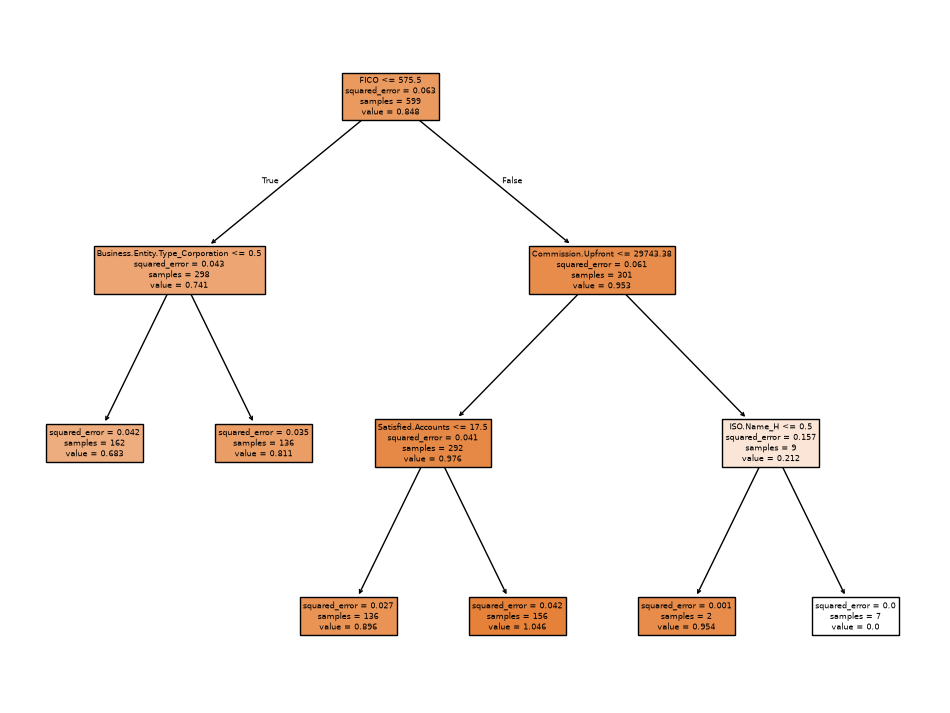


8c: The previously identified anomalies of having 0.0 PRSM score is characterized by: 
FICO > 575.5
Commission.Upfront > 29743.38
ISO.Name_H > 0.5

8d: The best loans have FICO > 575.5, Commission ≤ 29743, and Satisfied.Accounts > 17.5


In [8]:
from sklearn import tree
import sklearn

#Q8a. (1pt.)

reg_tree = tree.DecisionTreeRegressor(max_leaf_nodes=6, random_state=1940)
reg_tree.fit(X_train, y_train)

#Q8b. (1pt.)

fig = plt.figure(num=None, figsize=(12, 9))
tree.plot_tree(reg_tree, filled=True, feature_names=list(X.columns))
plt.show()

#Q8c. (2pts)  Your answer here.

print("\n8c: The previously identified anomalies of having 0.0 PRSM score is characterized by: \nFICO > 575.5\nCommission.Upfront > 29743.38\nISO.Name_H > 0.5")

#Q8d. (2pts.)  Your answer here.

print("\n8d: The best loans have FICO > 575.5, Commission ≤ 29743.38, and Satisfied.Accounts > 17.5.")


## Q9. Build a tree using cost complexity pruning
### 7 pts.

In this question you can use the code from the Module 8 notes as a guide. The key is to identify the relevant pieces of code to get the job done.

a. Set up a decision tree regressor and create its cost complexity pruning path. Save the alphas and impurities into variables.

b. Write a for loop that iterates over the alphas, creating a new tree for each value of alpha, that is then saved (append) into a list that is called rgrs.

c. Use the 'score' method to obtain the "scores" for both the training and test data sets. Save the scores into variables called 'train_scores' and 'test_scores'.

d. Find and print the index at which the maximum of the *test* scores appears (use the .idxmax() method).

e. Print out the test score (which is just the R-squared) for the best tree.







In [9]:
#9a. (2pts.)

dtr = tree.DecisionTreeRegressor(random_state=0)
path = dtr.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

#9b. (2pts.)

rgrs = []
for ccp_alpha in ccp_alphas:
    dtr = tree.DecisionTreeRegressor(random_state=0, ccp_alpha=ccp_alpha)
    dtr.fit(X_train, y_train)
    rgrs.append(dtr)

rgrs = rgrs[:-1]
ccp_alphas = ccp_alphas[:-1]


#9c. (1pt.)   

train_scores = [dtr.score(X_train, y_train) for dtr in rgrs]
test_scores = [dtr.score(X_test, y_test) for dtr in rgrs]

#9d. (1pt.)

best = pd.Series(test_scores).idxmax()
print("9d: Index of the best tree = " + str(best))

#9e. (1pt.)

print("9e: Test R-squared of the best tree = " + str(test_scores[best]))


9d: Index of the best tree = 555
9e: Test R-squared of the best tree = 0.31854897982206776
